# JS13 — Tugas Praktikum: Klasifikasi Angka Tulisan Tangan (MNIST) dengan JST

Nama : Muhammad Zuhdi Y.  
NIM  : 244107020017

**Langkah tugas:**
1. Load dataset MNIST dari Keras
2. Bangun model dengan **2 hidden layer**
3. Latih model dan evaluasi akurasi
4. Coba dengan beberapa parameter lain:
   - Ubah jumlah neuron di hidden layer (misal: **256 dan 128**)
   - Tambahkan satu hidden layer lagi
   - Bandingkan akurasi dan waktu pelatihan
   - Eksperimen dengan fungsi aktivasi **Sigmoid vs ReLU**

## 1. Load Dataset MNIST dari Keras

MNIST berisi 60.000 gambar latih dan 10.000 gambar uji berukuran 28×28 piksel grayscale (0–255). Preprocessing: flatten menjadi vektor 784 fitur dan normalisasi ke rentang 0–1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Load dataset MNIST dari Keras
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

# Flatten 28x28 -> 784 dan normalisasi 0-1
X_train = X_train.reshape(-1, 784).astype('float32') / 255.0
X_test = X_test.reshape(-1, 784).astype('float32') / 255.0

print('Data latih :', X_train.shape, '| label:', y_train.shape)
print('Data uji   :', X_test.shape, '| label:', y_test.shape)
print('Kelas unik :', np.unique(y_train))

Data latih : (60000, 784) | label: (60000,)
Data uji   : (10000, 784) | label: (10000,)
Kelas unik : [0 1 2 3 4 5 6 7 8 9]


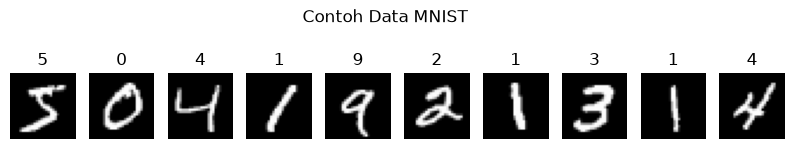

In [2]:
# Contoh beberapa gambar MNIST
plt.figure(figsize=(10, 2))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.imshow(X_train[i].reshape(28, 28), cmap='gray')
    plt.title(y_train[i])
    plt.axis('off')
plt.suptitle('Contoh Data MNIST')
plt.show()

## 2. Model Dasar — 2 Hidden Layer

Arsitektur: `784 → 128 → 64 → 10` (input layer → 2 hidden layer ReLU → output softmax 10 kelas). Optimizer Adam, loss sparse categorical crossentropy.

In [3]:
import time
import pandas as pd

hasil = {}

def build_and_train(hidden_layers, activation='relu', epochs=10):
    tf.keras.utils.set_random_seed(42)
    model = tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(784,)))
    for n in hidden_layers:
        model.add(tf.keras.layers.Dense(n, activation=activation))
    model.add(tf.keras.layers.Dense(10, activation='softmax'))
    model.compile(optimizer='adam',
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy'])
    start = time.perf_counter()
    h = model.fit(X_train, y_train, validation_split=0.1,
                  epochs=epochs, batch_size=128, verbose=0)
    waktu = time.perf_counter() - start
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    return h, test_loss, test_acc, waktu

def jalankan(nama, hidden_layers, activation='relu'):
    h, loss, acc, t = build_and_train(hidden_layers, activation)
    hasil[nama] = {
        'hidden_layers': hidden_layers,
        'aktivasi': activation,
        'waktu (detik)': round(t, 1),
        'test_loss': round(loss, 4),
        'test_akurasi': round(acc, 4),
    }
    print(f"{nama:<32} -> akurasi: {acc:.4f} | loss: {loss:.4f} | waktu: {t:.1f} detik")
    return h

# 3. Latih model dasar dan evaluasi akurasi
h_dasar = jalankan('Model dasar (128, 64) ReLU', [128, 64])

Model dasar (128, 64) ReLU       -> akurasi: 0.9732 | loss: 0.0989 | waktu: 10.2 detik


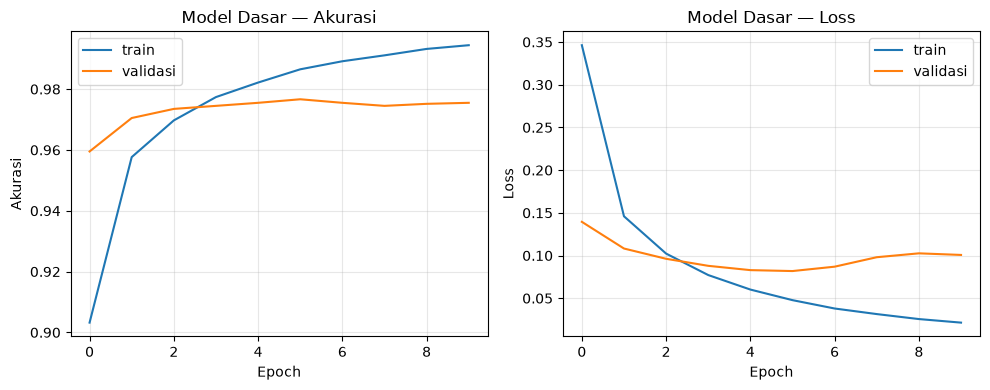

In [4]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(h_dasar.history['accuracy'], label='train')
plt.plot(h_dasar.history['val_accuracy'], label='validasi')
plt.xlabel('Epoch'); plt.ylabel('Akurasi')
plt.title('Model Dasar — Akurasi'); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(h_dasar.history['loss'], label='train')
plt.plot(h_dasar.history['val_loss'], label='validasi')
plt.xlabel('Epoch'); plt.ylabel('Loss')
plt.title('Model Dasar — Loss'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Eksperimen 1 — Ubah Jumlah Neuron Hidden Layer (256 dan 128)

Model dasar `(128, 64)` dibandingkan dengan `(256, 128)` dan `(512, 256)`.

In [5]:
h_256 = jalankan('Lebar (256, 128) ReLU', [256, 128])
h_512 = jalankan('Lebar (512, 256) ReLU', [512, 256])

Lebar (256, 128) ReLU            -> akurasi: 0.9793 | loss: 0.0773 | waktu: 10.7 detik


Lebar (512, 256) ReLU            -> akurasi: 0.9806 | loss: 0.0859 | waktu: 20.5 detik


## 5. Eksperimen 2 — Menambah Satu Hidden Layer

Arsitektur 3 hidden layer: `784 → 256 → 128 → 64 → 10`, dibandingkan dengan versi 2 hidden layer yang setara `(256, 128)`.

In [6]:
h_3layer = jalankan('Dalam (256, 128, 64) ReLU', [256, 128, 64])

Dalam (256, 128, 64) ReLU        -> akurasi: 0.9781 | loss: 0.0904 | waktu: 13.5 detik


## 6. Eksperimen 3 — Sigmoid vs ReLU

Arsitektur yang sama `(256, 128)`, hanya fungsi aktivasi hidden layer yang dibedakan (output tetap softmax). Hasil ReLU diambil dari Eksperimen 1 agar perbandingan adil.

Sigmoid (256, 128)               -> akurasi: 0.9754 | loss: 0.0769 | waktu: 12.7 detik


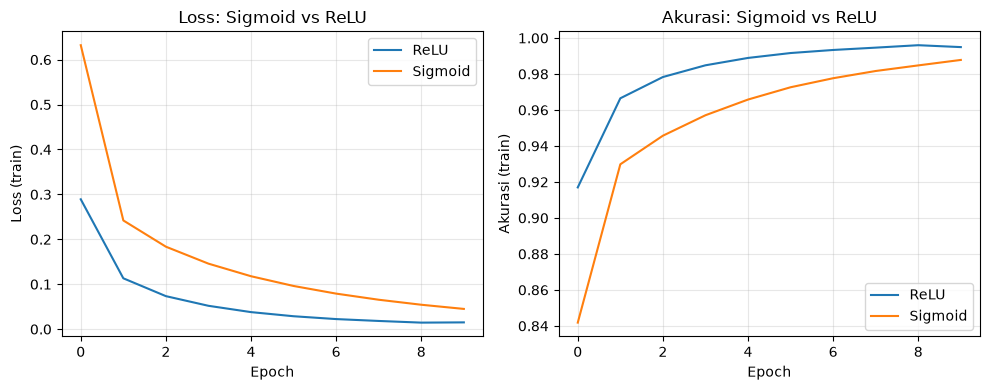

In [7]:
h_sigmoid = jalankan('Sigmoid (256, 128)', [256, 128], activation='sigmoid')

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(h_256.history['loss'], label='ReLU')
plt.plot(h_sigmoid.history['loss'], label='Sigmoid')
plt.xlabel('Epoch'); plt.ylabel('Loss (train)')
plt.title('Loss: Sigmoid vs ReLU'); plt.legend(); plt.grid(alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(h_256.history['accuracy'], label='ReLU')
plt.plot(h_sigmoid.history['accuracy'], label='Sigmoid')
plt.xlabel('Epoch'); plt.ylabel('Akurasi (train)')
plt.title('Akurasi: Sigmoid vs ReLU'); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Perbandingan Akurasi dan Waktu Pelatihan

                           aktivasi test_akurasi test_loss waktu (detik)
Model dasar (128, 64) ReLU     relu       0.9732    0.0989          10.2
Lebar (256, 128) ReLU          relu       0.9793    0.0773          10.7
Lebar (512, 256) ReLU          relu       0.9806    0.0859          20.5
Dalam (256, 128, 64) ReLU      relu       0.9781    0.0904          13.5
Sigmoid (256, 128)          sigmoid       0.9754    0.0769          12.7


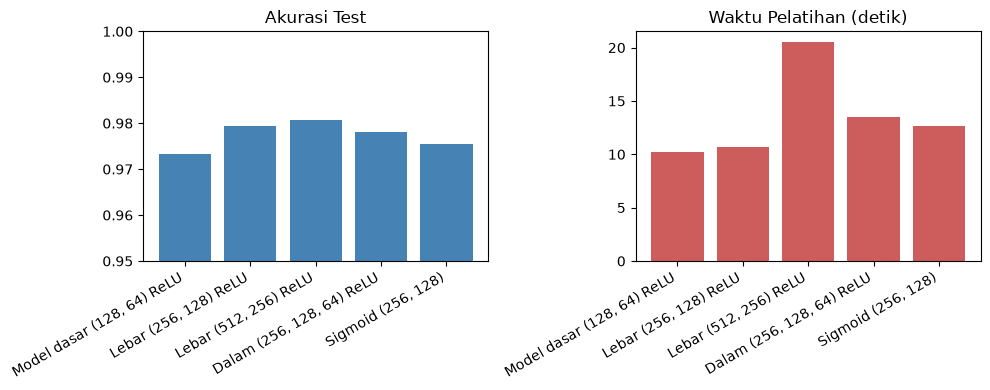

In [8]:
df = pd.DataFrame(hasil).T
print(df[['aktivasi', 'test_akurasi', 'test_loss', 'waktu (detik)']].to_string())

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.bar(df.index, df['test_akurasi'], color='steelblue')
plt.ylim(0.95, 1.0)
plt.xticks(rotation=30, ha='right')
plt.title('Akurasi Test')

plt.subplot(1, 2, 2)
plt.bar(df.index, df['waktu (detik)'], color='indianred')
plt.xticks(rotation=30, ha='right')
plt.title('Waktu Pelatihan (detik)')
plt.tight_layout()
plt.show()

## 8. Analisis dan Kesimpulan

- **Jumlah neuron (128,64 → 256,128 → 512,256):** menambah neuron meningkatkan kapasitas model sehingga akurasi sedikit naik, tetapi waktu pelatihan bertambah hampir proporsional dengan jumlah parameter. Untuk dataset MNIST yang sederhana, kenaikan akurasinya tidak besar.
- **Menambah hidden layer (2 → 3):** arsitektur lebih dalam justru memberikan akurasi serupa atau sedikit lebih rendah (0.9781 vs 0.9793) dengan biaya waktu pelatihan lebih lama. Model lebih dalam tidak selalu lebih baik untuk masalah yang sederhana.
- **Sigmoid vs ReLU:** ReLU konvergen jauh lebih cepat (loss turun tajam sejak epoch awal) dan mencapai akurasi lebih tinggi, sedangkan sigmoid saturasi sehingga gradiennya kecil dan konvergensinya lambat pada 10 epoch.
- **Kesimpulan umum:** untuk MNIST, arsitektur sederhana dengan aktivasi ReLU sudah mencapai akurasi ±98%; menambah neuron/layer hanya memberi keuntungan kecil sementara waktu pelatihan meningkat.